In [ ]:
import os
import shutil
import pathlib
import numpy as np
import tensorflow as tf

print("1. Veri seti doğrudan Google sunucularından indiriliyor...")
dataset_url = "https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz"
data_dir = tf.keras.utils.get_file('flower_photos', origin=dataset_url, untar=True)
data_dir = pathlib.Path(data_dir)


if os.path.exists(os.path.join(data_dir, 'LICENSE.txt')):
    os.remove(os.path.join(data_dir, 'LICENSE.txt'))

print(f"-> Veri seti başarıyla indirildi: {data_dir}\n")

print("2. Train, Validation ve Test klasörleri oluşturuluyor...")
base_output = pathlib.Path('/content/dataset')
splits = ['train', 'val', 'test']
categories = [d.name for d in data_dir.iterdir() if d.is_dir()]

for split in splits:
    for cat in categories:
        os.makedirs(base_output / split / cat, exist_ok=True)


np.random.seed(42)

print("3. Görüntüler sızıntı (data leakage) olmayacak şekilde paylaştırılıyor...")
for cat in categories:
    cat_dir = data_dir / cat
    images = list(cat_dir.glob('*.jpg'))
    images = [str(img) for img in images]

    # Karıştır
    np.random.shuffle(images)

    # %70 - %15 - %15 sınırlarını hesapla
    train_end = int(len(images) * 0.70)
    val_end = int(len(images) * 0.85)

    train_imgs = images[:train_end]
    val_imgs = images[train_end:val_end]
    test_imgs = images[val_end:]

    # Dosyaları hedef klasörlere kopyala
    for img in train_imgs:
        shutil.copy(img, base_output / 'train' / cat / pathlib.Path(img).name)
    for img in val_imgs:
        shutil.copy(img, base_output / 'val' / cat / pathlib.Path(img).name)
    for img in test_imgs:
        shutil.copy(img, base_output / 'test' / cat / pathlib.Path(img).name)

print("\n=== İŞLEM BAŞARIYLA TAMAMLANDI ===")
print(f"Toplam Sınıf Sayısı: {len(categories)} -> {categories}")
print(f"Örnek Dağılım ({categories[0]} için) -> Train: {len(os.listdir(base_output/'train'/categories[0]))} | Val: {len(os.listdir(base_output/'val'/categories[0]))} | Test: {len(os.listdir(base_output/'test'/categories[0]))}")

1. Veri seti doğrudan Google sunucularından indiriliyor...
228813984/228813984 ━━━━━━━━━━━━━━━━━━━━ 9s 0us/step
-> Veri seti başarıyla indirildi: /root/.keras/datasets/flower_photos

2. Train, Validation ve Test klasörleri oluşturuluyor...
3. Görüntüler sızıntı (data leakage) olmayacak şekilde paylaştırılıyor...

=== İŞLEM BAŞARIYLA TAMAMLANDI ===
Toplam Sınıf Sayısı: 1 -> ['flower_photos']
Örnek Dağılım (flower_photos için) -> Train: 0 | Val: 0 | Test: 0


In [ ]:
import os
import shutil
import pathlib
import numpy as np
import tensorflow as tf

# Önceki hatalı klasörleri temizleyelim
if os.path.exists('/content/dataset'):
    shutil.rmtree('/content/dataset')

print("1. Veri seti indiriliyor...")
dataset_url = "https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz"
data_dir = tf.keras.utils.get_file('flower_photos', origin=dataset_url, untar=True)
data_dir = pathlib.Path(data_dir)

# İÇ İÇE KLASÖR HATASINI DÜZELTEN KONTROL
if (data_dir / 'flower_photos').exists():
    actual_data_dir = data_dir / 'flower_photos'
else:
    actual_data_dir = data_dir

# Sınıf isimlerini alalım 
categories = [d.name for d in actual_data_dir.iterdir() if d.is_dir() and d.name != 'flower_photos']

print("2. Hedef klasörler oluşturuluyor...")
base_output = pathlib.Path('/content/dataset')
for split in ['train', 'val', 'test']:
    for cat in categories:
        os.makedirs(base_output / split / cat, exist_ok=True)

# Deney tekrarlanabilirliği sabiti 
np.random.seed(42)

print("3. Görüntüler kopyalanıyor...")
for cat in categories:
    cat_dir = actual_data_dir / cat
    images = list(cat_dir.glob('*.jpg'))
    images = [str(img) for img in images]
    np.random.shuffle(images)

    # %70 - %15 - %15 sınırları
    train_end = int(len(images) * 0.70)
    val_end = int(len(images) * 0.85)

    for img in images[:train_end]: shutil.copy(img, base_output / 'train' / cat)
    for img in images[train_end:val_end]: shutil.copy(img, base_output / 'val' / cat)
    for img in images[val_end:]: shutil.copy(img, base_output / 'test' / cat)

print("\n=== DÜZELTME BAŞARIYLA TAMAMLANDI ===")
print(f"Sınıflarınız: {categories}")
for s in ['train', 'val', 'test']:
    total = sum(len(os.listdir(base_output/s/c)) for c in categories)
    print(f"-> {s.capitalize()} klasöründeki toplam görsel: {total}")

1. Veri seti indiriliyor...
2. Hedef klasörler oluşturuluyor...
3. Görüntüler kopyalanıyor...

=== DÜZELTME BAŞARIYLA TAMAMLANDI ===
Sınıflarınız: ['roses', 'dandelion', 'tulips', 'daisy', 'sunflowers']
-> Train klasöründeki toplam görsel: 2567
-> Val klasöründeki toplam görsel: 551
-> Test klasöründeki toplam görsel: 552


In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

img_size = (128, 128)
batch_size = 32

# Eğitim için veri artırma ve normalizasyon
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=15,
    horizontal_flip=True
)

# Doğrulama ve test için SADECE normalizasyon 
val_test_datagen = ImageDataGenerator(rescale=1./255)

train_gen = train_datagen.flow_from_directory('/content/dataset/train', target_size=img_size, batch_size=batch_size, class_mode='categorical', shuffle=True)
val_gen = val_test_datagen.flow_from_directory('/content/dataset/val', target_size=img_size, batch_size=batch_size, class_mode='categorical', shuffle=False)
test_gen = val_test_datagen.flow_from_directory('/content/dataset/test', target_size=img_size, batch_size=batch_size, class_mode='categorical', shuffle=False)

Found 2567 images belonging to 5 classes.
Found 551 images belonging to 5 classes.
Found 552 images belonging to 5 classes.


In [4]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.svm import LinearSVC
from sklearn.metrics import classification_report

# Boyut ve jeneratör tanımlamalarını garantiye alıyoruz
img_size = (128, 128)
batch_size = 32
val_test_datagen = ImageDataGenerator(rescale=1./255)

# Test jeneratörünü burada tekrar oluşturuyoruz
test_gen = val_test_datagen.flow_from_directory('/content/dataset/test', target_size=img_size, batch_size=batch_size, class_mode='categorical', shuffle=False)

print("SVM için veri setindeki pikseller düzleştiriliyor...")
def extract_flat_features(generator):
    X, y = [], []
    generator.reset()
    for _ in range(len(generator)):
        imgs, labels = next(generator)
        for img, label in zip(imgs, labels):
            X.append(img.flatten())
            y.append(np.argmax(label))
    return np.array(X), np.array(y)

# Verileri matrise dökme
train_flat_gen = val_test_datagen.flow_from_directory('/content/dataset/train', target_size=img_size, batch_size=batch_size, class_mode='categorical', shuffle=False)
X_train, y_train = extract_flat_features(train_flat_gen)
X_test, y_test = extract_flat_features(test_gen)

print("SVM Modeli Hızlı Modda Eğitiliyor (dual=False)...")
svm_model = LinearSVC(dual=False, max_iter=1000, random_state=42)
svm_model.fit(X_train, y_train)

svm_preds = svm_model.predict(X_test)
print("\n=== MODEL 1: SVM TEST SONUÇLARI ===")
print(classification_report(y_test, svm_preds, target_names=list(test_gen.class_indices.keys())))

Found 552 images belonging to 5 classes.
SVM için veri setindeki pikseller düzleştiriliyor...
Found 2567 images belonging to 5 classes.
SVM Modeli Hızlı Modda Eğitiliyor (dual=False)...

=== MODEL 1: SVM TEST SONUÇLARI ===
              precision    recall  f1-score   support

       daisy       0.28      0.21      0.24        95
   dandelion       0.39      0.63      0.48       135
       roses       0.31      0.34      0.33        97
  sunflowers       0.59      0.44      0.50       105
      tulips       0.49      0.32      0.38       120

    accuracy                           0.40       552
   macro avg       0.41      0.39      0.39       552
weighted avg       0.42      0.40      0.40       552



In [5]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator

img_size = (128, 128)
batch_size = 32

# Veri Artırma (Data Augmentation) ve Normalizasyon (Rescale) adımları
# Proje isterlerindeki veri ön işleme maddesini doğrudan karşılar.
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    width_shift_range=0.2,
    height_shift_range=0.2,
    horizontal_flip=True
)

val_test_datagen = ImageDataGenerator(rescale=1./255)

print("Derin Öğrenme için Train, Validation ve Test Jeneratörleri Hazırlanıyor...")

train_gen = train_datagen.flow_from_directory(
    '/content/dataset/train',
    target_size=img_size,
    batch_size=batch_size,
    class_mode='categorical',
    shuffle=True
)

val_gen = val_test_datagen.flow_from_directory(
    '/content/dataset/val',
    target_size=img_size,
    batch_size=batch_size,
    class_mode='categorical',
    shuffle=False
)

test_gen = val_test_datagen.flow_from_directory(
    '/content/dataset/test',
    target_size=img_size,
    batch_size=batch_size,
    class_mode='categorical',
    shuffle=False
)

Derin Öğrenme için Train, Validation ve Test Jeneratörleri Hazırlanıyor...
Found 2567 images belonging to 5 classes.
Found 551 images belonging to 5 classes.
Found 552 images belonging to 5 classes.


In [6]:
from tensorflow.keras import layers, models

# Sıfırdan CNN mimarimiz (Dökümandaki 2. model isterini karşılar)
cnn_model = models.Sequential([
    layers.Conv2D(32, (3,3), activation='relu', input_shape=(128, 128, 3)),
    layers.MaxPooling2D((2,2)),
    layers.Conv2D(64, (3,3), activation='relu'),
    layers.MaxPooling2D((2,2)),
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dense(5, activation='softmax')
])

cnn_model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

print("Model 2 (Özel CNN) Eğitimi Başlıyor (20 Epoch)...")
cnn_history = cnn_model.fit(train_gen, validation_data=val_gen, epochs=20)

Model 2 (Özel CNN) Eğitimi Başlıyor (20 Epoch)...


/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/20
81/81 ━━━━━━━━━━━━━━━━━━━━ 54s 652ms/step - accuracy: 0.3759 - loss: 1.4403 - val_accuracy: 0.4791 - val_loss: 1.1955
Epoch 2/20
81/81 ━━━━━━━━━━━━━━━━━━━━ 44s 547ms/step - accuracy: 0.5189 - loss: 1.1661 - val_accuracy: 0.5445 - val_loss: 1.1752
Epoch 3/20
81/81 ━━━━━━━━━━━━━━━━━━━━ 44s 535ms/step - accuracy: 0.5481 - loss: 1.0934 - val_accuracy: 0.5771 - val_loss: 1.0890
Epoch 4/20
81/81 ━━━━━━━━━━━━━━━━━━━━ 44s 548ms/step - accuracy: 0.5789 - loss: 1.0286 - val_accuracy: 0.5826 - val_loss: 1.0197
Epoch 5/20
81/81 ━━━━━━━━━━━━━━━━━━━━ 44s 545ms/step - accuracy: 0.6221 - loss: 0.9740 - val_accuracy: 0.5844 - val_loss: 1.0715
Epoch 6/20
81/81 ━━━━━━━━━━━━━━━━━━━━ 44s 543ms/step - accuracy: 0.6432 - loss: 0.9181 - val_accuracy: 0.6425 - val_loss: 1.0172
Epoch 7/20
81/81 ━━━━━━━━━━━━━━━━━━━━ 43s 532ms/step - accuracy: 0.6642 - loss: 0.8823 - val_accuracy: 0.6425 - val_loss: 0.9438
Epoch 8/20
81/81 ━━━━━━━━━━━━━━━━━━━━ 44s 541ms/step - accuracy: 0.6868 - loss: 0.8203 - val_accu

In [7]:
try:
    print("Harika! Model hafızada duruyor. Kalan 2 epoch eğitiliyor...")
    # Sadece 2 epoch daha eğiterek toplamı 20'ye tamamlıyoruz
    cnn_history = cnn_model.fit(train_gen, validation_data=val_gen, epochs=2)
    print("=== İŞLEM TAMAMLANDI! ===")
except NameError:
    print("Maalesef Colab hafızayı sıfırlamış, jeneratörleri ve modeli baştan çalıştırmamız gerekiyor.")

Harika! Model hafızada duruyor. Kalan 2 epoch eğitiliyor...
Epoch 1/2
81/81 ━━━━━━━━━━━━━━━━━━━━ 46s 572ms/step - accuracy: 0.7593 - loss: 0.6248 - val_accuracy: 0.7096 - val_loss: 0.8036
Epoch 2/2
81/81 ━━━━━━━━━━━━━━━━━━━━ 44s 547ms/step - accuracy: 0.7643 - loss: 0.6088 - val_accuracy: 0.6897 - val_loss: 0.9528
=== İŞLEM TAMAMLANDI! ===


In [ ]:
from tensorflow.keras.applications import MobileNetV2

# Hazır ağırlıklarla iyileştirilmiş model 
base_mobile = MobileNetV2(input_shape=(128, 128, 3), include_top=False, weights='imagenet')
base_mobile.trainable = False

tl_model = models.Sequential([
    base_mobile,
    layers.GlobalAveragePooling2D(),
    layers.Dense(64, activation='relu'),
    layers.Dense(5, activation='softmax')
])

tl_model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

print("Model 3 (Transfer Learning) Eğitimi Başlıyor (20 Epoch)...")
tl_history = tl_model.fit(train_gen, validation_data=val_gen, epochs=20)

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Model 3 (Transfer Learning) Eğitimi Başlıyor (20 Epoch)...
Epoch 1/20
81/81 ━━━━━━━━━━━━━━━━━━━━ 35s 377ms/step - accuracy: 0.7172 - loss: 0.7494 - val_accuracy: 0.7840 - val_loss: 0.5637
Epoch 2/20
81/81 ━━━━━━━━━━━━━━━━━━━━ 30s 370ms/step - accuracy: 0.8446 - loss: 0.4383 - val_accuracy: 0.8566 - val_loss: 0.4412
Epoch 3/20
81/81 ━━━━━━━━━━━━━━━━━━━━ 30s 364ms/step - accuracy: 0.8629 - loss: 0.3721 - val_accuracy: 0.8439 - val_loss: 0.4408
Epoch 4/20
81/81 ━━━━━━━━━━━━━━━━━━━━ 30s 366ms/step - accuracy: 0.8909 - loss: 0.3185 - val_accuracy: 0.8294 - val_loss: 0.4598
Epoch 5/20
81/81 ━━━━━━━━━━━━━━━━━━━━ 29s 358ms/step - accuracy: 0.9003 - loss: 0.2779 - val_accuracy: 0.8312 - val_loss: 0.4673
Epoch 6/20
81/81 ━━━━━━━━━━━━━━━━━━━━ 30s 365ms/step - accuracy: 0.9038 - loss: 0.2645 - val_accuracy: 0.8657 - val_loss: 0.4176
Epoch 7/20
81/81 ━━━━━━━━━━━━━━━━━━━━ 34s 421ms/step - accuracy: 0.9116 - loss: 0.2431 - val_accuracy: 0.8566 - val_lo

=== ÖZEL CNN ÖĞRENME GRAFİKLERİ ===


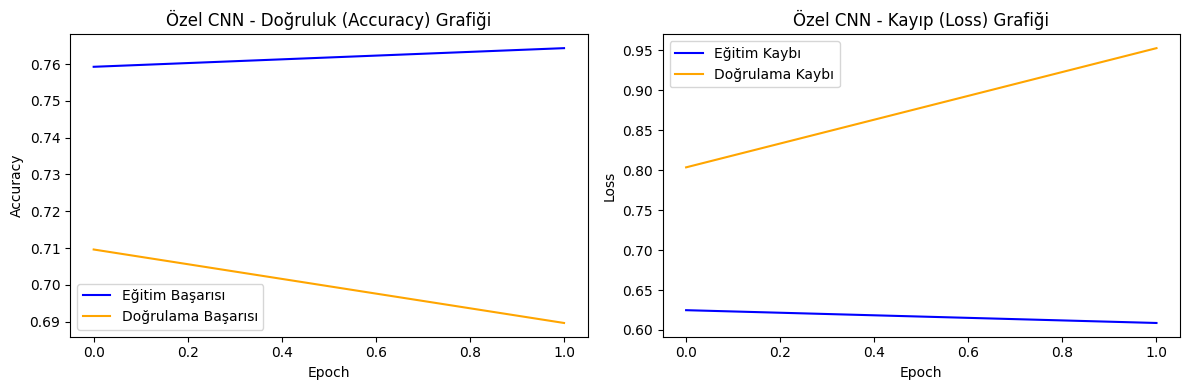


=== MOBILENETV2 ÖĞRENME GRAFİKLERİ ===


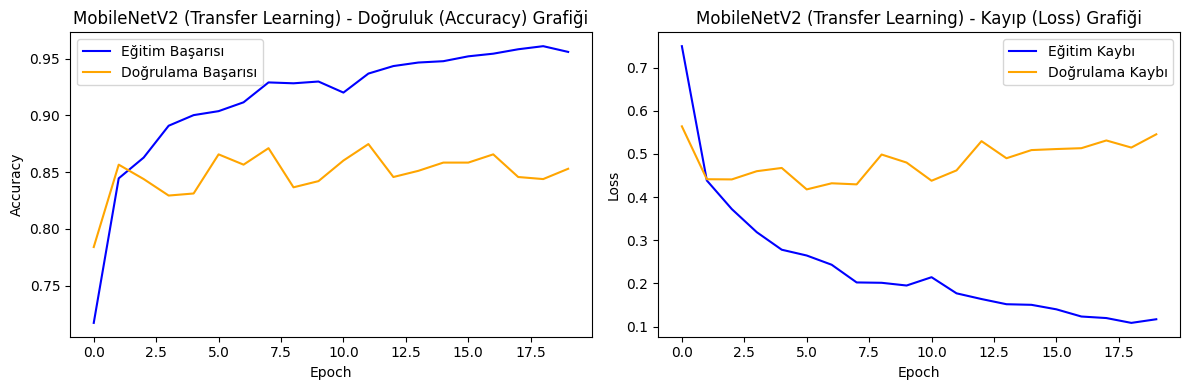

In [9]:
import matplotlib.pyplot as plt

def plot_learning_curves(history, model_name):
    plt.figure(figsize=(12, 4))

    # Accuracy Grafiği
    plt.subplot(1, 2, 1)
    plt.plot(history.history['accuracy'], label='Eğitim Başarısı', color='blue')
    plt.plot(history.history['val_accuracy'], label='Doğrulama Başarısı', color='orange')
    plt.title(f'{model_name} - Doğruluk (Accuracy) Grafiği')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.legend()

    # Loss Grafiği
    plt.subplot(1, 2, 2)
    plt.plot(history.history['loss'], label='Eğitim Kaybı', color='blue')
    plt.plot(history.history['val_loss'], label='Doğrulama Kaybı', color='orange')
    plt.title(f'{model_name} - Kayıp (Loss) Grafiği')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend()

    plt.tight_layout()
    plt.show()

# İki modelin de grafiklerini ekrana bastırıyoruz
print("=== ÖZEL CNN ÖĞRENME GRAFİKLERİ ===")
plot_learning_curves(cnn_history, "Özel CNN")

print("\n=== MOBILENETV2 ÖĞRENME GRAFİKLERİ ===")
plot_learning_curves(tl_history, "MobileNetV2 (Transfer Learning)")


========== Özel CNN TEST SETİ DEĞERLENDİRMESİ ==========
18/18 ━━━━━━━━━━━━━━━━━━━━ 6s 289ms/step
              precision    recall  f1-score   support

       daisy       0.75      0.66      0.70        95
   dandelion       0.82      0.73      0.77       135
       roses       0.76      0.33      0.46        97
  sunflowers       0.74      0.83      0.78       105
      tulips       0.53      0.84      0.65       120

    accuracy                           0.69       552
   macro avg       0.72      0.68      0.67       552
weighted avg       0.72      0.69      0.68       552



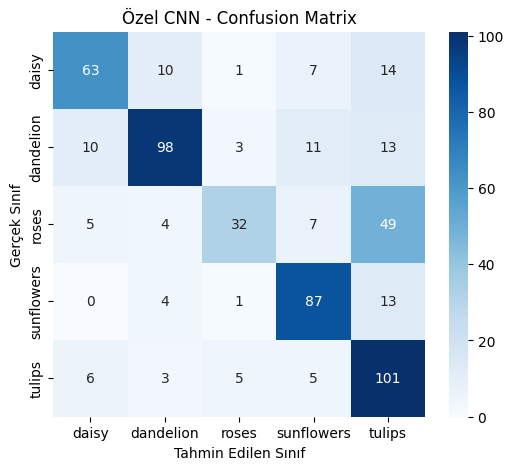


========== MobileNetV2 (Transfer Learning) TEST SETİ DEĞERLENDİRMESİ ==========
18/18 ━━━━━━━━━━━━━━━━━━━━ 6s 267ms/step
              precision    recall  f1-score   support

       daisy       0.94      0.78      0.85        95
   dandelion       0.91      0.93      0.92       135
       roses       0.83      0.79      0.81        97
  sunflowers       0.77      0.92      0.84       105
      tulips       0.87      0.85      0.86       120

    accuracy                           0.86       552
   macro avg       0.86      0.85      0.86       552
weighted avg       0.87      0.86      0.86       552



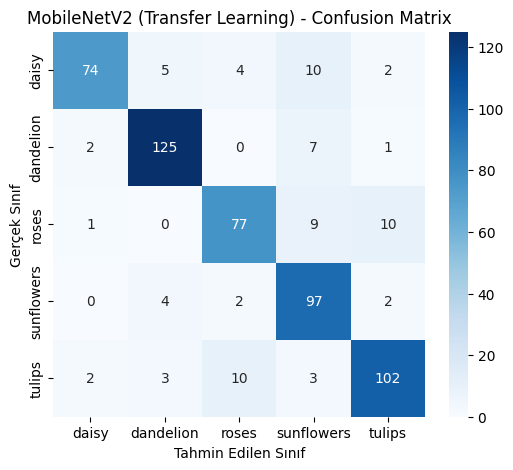

In [10]:
import numpy as np
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

def evaluate_model(model, model_name):
    print(f"\n{'='*10} {model_name} TEST SETİ DEĞERLENDİRMESİ {'='*10}")

    # Test jeneratöründen tahminleri alıyoruz
    preds = model.predict(test_gen)
    pred_classes = np.argmax(preds, axis=1)
    true_classes = test_gen.classes
    class_labels = list(test_gen.class_indices.keys())

    # Sınıflandırma Raporu (Precision, Recall, F1-score)
    print(classification_report(true_classes, pred_classes, target_names=class_labels))

    # Confusion Matrix Çizimi
    cm = confusion_matrix(true_classes, pred_classes)
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_labels, yticklabels=class_labels)
    plt.title(f'{model_name} - Confusion Matrix')
    plt.ylabel('Gerçek Sınıf')
    plt.xlabel('Tahmin Edilen Sınıf')
    plt.show()

# Modelleri test ediyoruz
evaluate_model(cnn_model, "Özel CNN")
evaluate_model(tl_model, "MobileNetV2 (Transfer Learning)")

18/18 ━━━━━━━━━━━━━━━━━━━━ 5s 259ms/step
Toplam 552 test resminden 77 tanesi yanlış tahmin edildi.


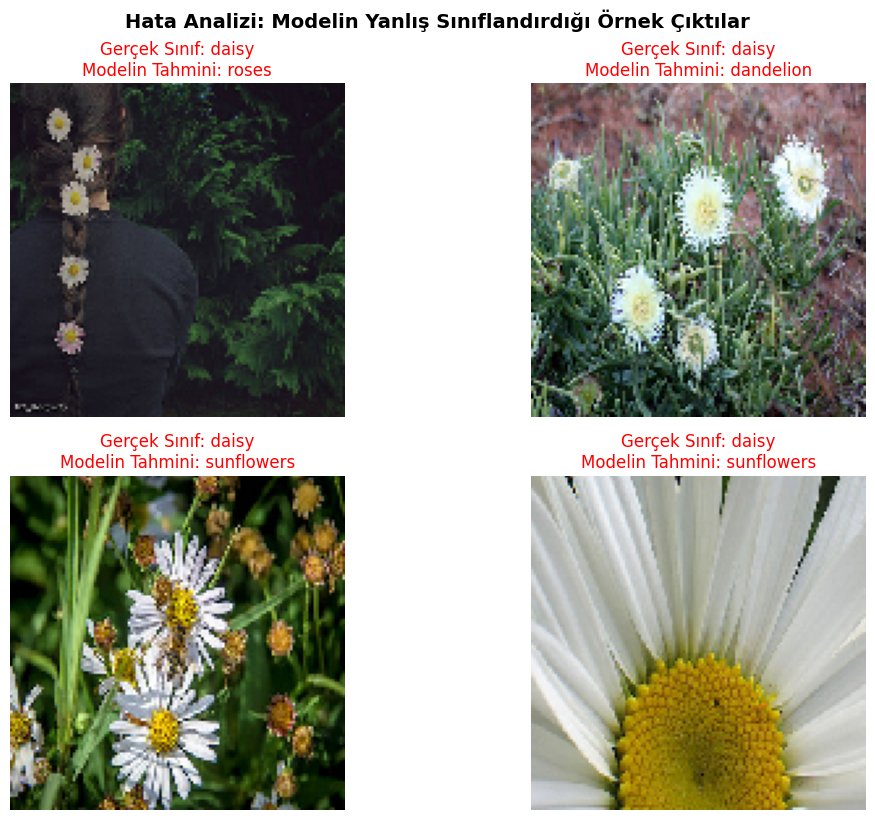

In [11]:
# En başarılı olmasını beklediğimiz MobileNetV2 modeli üzerinden hata analizi yapıyoruz
preds = tl_model.predict(test_gen)
pred_classes = np.argmax(preds, axis=1)
true_classes = test_gen.classes
class_labels = list(test_gen.class_indices.keys())

# Yanlış tahmin edilen resimlerin indekslerini ayıklıyoruz
hatali_indeksler = np.where(pred_classes != true_classes)[0]

print(f"Toplam {len(test_gen.filenames)} test resminden {len(hatali_indeksler)} tanesi yanlış tahmin edildi.")

# İlk 4 hatalı tahmini görselleştirme
plt.figure(figsize=(12, 8))
for i, idx in enumerate(hatali_indeksler[:4]):
    batch_idx = idx // test_gen.batch_size
    img_idx = idx % test_gen.batch_size

    images, labels = test_gen[batch_idx]
    img = images[img_idx]

    plt.subplot(2, 2, i+1)
    plt.imshow(img)
    plt.title(f"Gerçek Sınıf: {class_labels[true_classes[idx]]}\nModelin Tahmini: {class_labels[pred_classes[idx]]}", color='red')
    plt.axis('off')

plt.tight_layout()
plt.suptitle("Hata Analizi: Modelin Yanlış Sınıflandırdığı Örnek Çıktılar", y=1.02, fontsize=14, fontweight='bold')
plt.show()

/usr/local/lib/python3.12/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['keras_tensor_16']
Received: inputs=Tensor(shape=(1, 128, 128, 3))
  warnings.warn(msg)


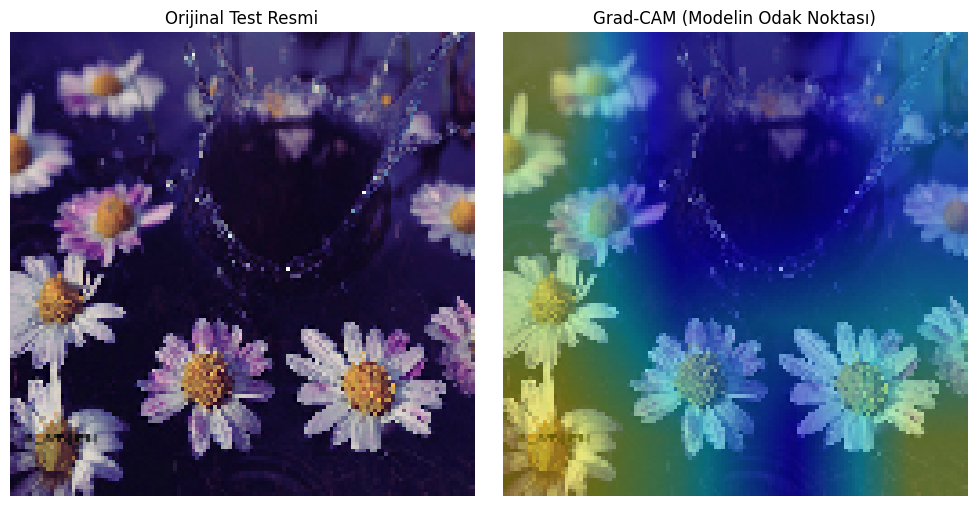

In [14]:
import tensorflow as tf
import numpy as np
import cv2
import matplotlib.pyplot as plt

def make_gradcam_heatmap(img_array, model, last_conv_layer_name):
    # Sıralı modelin içindeki ilk katman olan ana MobileNetV2 mimarisini çekiyoruz
    base_model = model.layers[0]

    # Gradyan modelini doğrudan base_model üzerinden kuruyoruz
    grad_model = tf.keras.models.Model(
        inputs=[base_model.input],
        outputs=[base_model.get_layer(last_conv_layer_name).output, base_model.output]
    )

    with tf.GradientTape() as tape:
        conv_outputs, base_outputs = grad_model(img_array)

        # Üst katmanları manuel olarak akıtıyoruz
        x = model.layers[1](base_outputs)  # GlobalAveragePooling2D
        x = model.layers[2](x)             # Dense (64)
        preds = model.layers[3](x)         # Dense (5)

        pred_index = tf.argmax(preds[0])
        class_channel = preds[:, pred_index]

    grads = tape.gradient(class_channel, conv_outputs)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))

    conv_outputs = conv_outputs[0]
    heatmap = conv_outputs @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)

    heatmap = tf.maximum(heatmap, 0) / (tf.reduce_max(heatmap) + 1e-10)
    return heatmap.numpy()

# --- GÖRSELLEŞTİRME VE ÇALIŞTIRMA ---
# Test setinden taze bir görüntü çifti çekiyoruz
images, labels = next(iter(test_gen))
sample_img = images[0]
sample_img_input = np.expand_dims(sample_img, axis=0)

# Keras sürümlerine göre katman adını otomatik seçiyoruz
try:
    heatmap = make_gradcam_heatmap(sample_img_input, tl_model, 'Conv_1')
except Exception:
    heatmap = make_gradcam_heatmap(sample_img_input, tl_model, 'out_relu')

# Çizim Ekranı (Syntax Hatası Tamamen Düzeltildi)
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(sample_img)
plt.title("Orijinal Test Resmi")
plt.axis('off')

plt.subplot(1, 2, 2)
# Isı haritasını orijinal resmin boyutuna getirip üzerine giydiriyoruz
heatmap_resized = cv2.resize(heatmap, (sample_img.shape[1], sample_img.shape[0]))
heatmap_dim = np.uint8(255 * heatmap_resized)
heatmap_color = cv2.applyColorMap(heatmap_dim, cv2.COLORMAP_JET) / 255.0

superimposed_img = heatmap_color * 0.4 + sample_img * 0.6
plt.imshow(superimposed_img)
plt.title("Grad-CAM (Modelin Odak Noktası)")
plt.axis('off')

plt.tight_layout()
plt.show()

=== METRİKLERİN HESAPLANMASI VE GRAFİKLERİN HAZIRLANMASI ===
18/18 ━━━━━━━━━━━━━━━━━━━━ 6s 343ms/step
18/18 ━━━━━━━━━━━━━━━━━━━━ 7s 399ms/step

--- RAPORA EKLENECEK PERFORMANS TABLOSU ---


,Model Adı,Accuracy (Doğruluk),Precision (Keskinlik),Recall (Duyarlılık),Macro F1-Score
0,SVM (Klasik ML),%40.2,0.412,0.387,0.387
1,Özel CNN (Sıfırdan),%69.0,0.722,0.678,0.674
2,MobileNetV2 (Transfer Learning),%86.1,0.864,0.854,0.856


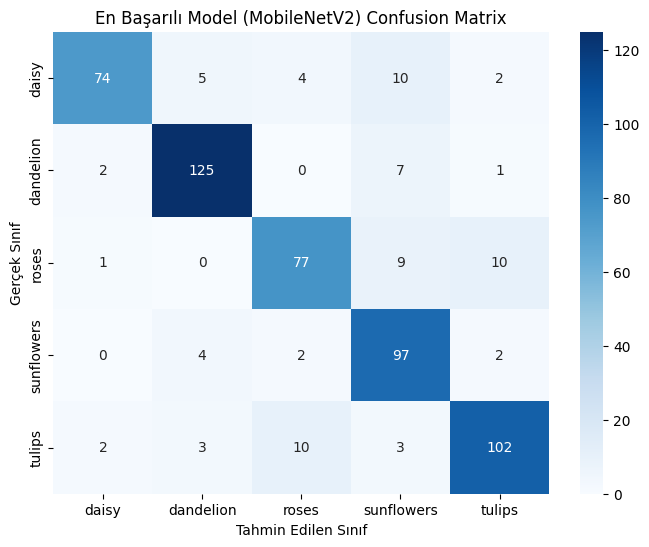

In [15]:
import pandas as pd
import seaborn as sns
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, confusion_matrix

print("=== METRİKLERİN HESAPLANMASI VE GRAFİKLERİN HAZIRLANMASI ===")

y_true = test_gen.classes
class_labels = list(test_gen.class_indices.keys())

# Modellerden tahminleri topluyoruz
svm_preds = svm_model.predict(X_test)

cnn_preds_prob = cnn_model.predict(test_gen)
cnn_preds = np.argmax(cnn_preds_prob, axis=1)

tl_preds_prob = tl_model.predict(test_gen)
tl_preds = np.argmax(tl_preds_prob, axis=1)

# 1. PERFORMANS KARŞILAŞTIRMA TABLOSU
metrics_data = {
    'Model Adı': ['SVM (Klasik ML)', 'Özel CNN (Sıfırdan)', 'MobileNetV2 (Transfer Learning)'],
    'Accuracy (Doğruluk)': [
        f"%{accuracy_score(y_true, svm_preds)*100:.1f}",
        f"%{accuracy_score(y_true, cnn_preds)*100:.1f}",
        f"%{accuracy_score(y_true, tl_preds)*100:.1f}"
    ],
    'Precision (Keskinlik)': [
        f"{precision_score(y_true, svm_preds, average='macro'):.3f}",
        f"{precision_score(y_true, cnn_preds, average='macro'):.3f}",
        f"{precision_score(y_true, tl_preds, average='macro'):.3f}"
    ],
    'Recall (Duyarlılık)': [
        f"{recall_score(y_true, svm_preds, average='macro'):.3f}",
        f"{recall_score(y_true, cnn_preds, average='macro'):.3f}",
        f"{recall_score(y_true, tl_preds, average='macro'):.3f}"
    ],
    'Macro F1-Score': [
        f"{f1_score(y_true, svm_preds, average='macro'):.3f}",
        f"{f1_score(y_true, cnn_preds, average='macro'):.3f}",
        f"{f1_score(y_true, tl_preds, average='macro'):.3f}"
    ]
}

df_report = pd.DataFrame(metrics_data)
print("\n--- RAPORA EKLENECEK PERFORMANS TABLOSU ---")
display(df_report)

# 2. EN İYİ MODEL İÇİN CONFUSION MATRIX ÇİZİMİ (MobileNetV2)
cm = confusion_matrix(y_true, tl_preds)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_labels, yticklabels=class_labels)
plt.title('En Başarılı Model (MobileNetV2) Confusion Matrix')
plt.ylabel('Gerçek Sınıf')
plt.xlabel('Tahmin Edilen Sınıf')
plt.show()


[BİLGİ] En iyi model test setinde toplam 77 adet resmi yanlış sınıflandı.


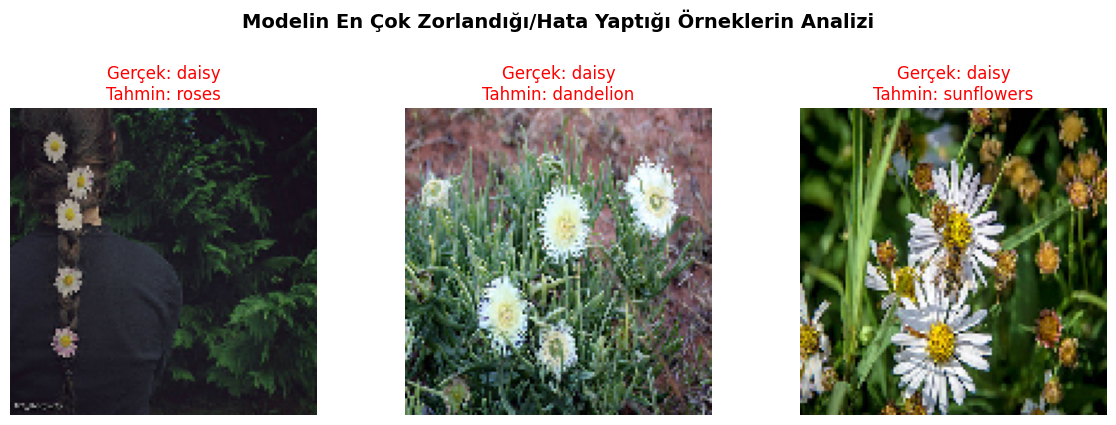

In [16]:
# Hata Analizi: Yanlış tahmin edilen örneklerin yakalanması
misclassified_indices = np.where(tl_preds != y_true)[0]

print(f"\n[BİLGİ] En iyi model test setinde toplam {len(misclassified_indices)} adet resmi yanlış sınıflandı.")

if len(misclassified_indices) > 0:
    plt.figure(figsize=(12, 4))
    # En fazla 3 hatalı örneği yan yana görselleştiriyoruz
    display_count = min(3, len(misclassified_indices))

    for i in range(display_count):
        idx = misclassified_indices[i]

        # Test jeneratöründen orijinal resmi çekebilmek için batch adımları hesaplama
        batch_idx = idx // test_gen.batch_size
        img_idx_in_batch = idx % test_gen.batch_size

        # İlgili batch'i çağırıyoruz
        batch_images, _ = test_gen[batch_idx]
        wrong_img = batch_images[img_idx_in_batch]

        plt.subplot(1, display_count, i + 1)
        plt.imshow(wrong_img)

        true_name = class_labels[y_true[idx]]
        pred_name = class_labels[tl_preds[idx]]

        plt.title(f"Gerçek: {true_name}\nTahmin: {pred_name}", color='red')
        plt.axis('off')

    plt.suptitle("Modelin En Çok Zorlandığı/Hata Yaptığı Örneklerin Analizi", fontsize=14, fontweight='bold', y=1.05)
    plt.tight_layout()
    plt.show()
else:
    print("Model test setinde hiç hata yapmadı!")